In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "..")  # repo root, so `core` is importable

from core import deempc, drmpc
from core.cartpole import cartpole
from core.generate_rng import trial_rngs
from core.offline import collect_offline_trajectories
from core.radius import estimate_radius

## Setup: SAAMPC vs. DRMPC vs. DeePC on the linearized cart-pole

Same system, spec and data as `drmpc/cart_pole_experiment.ipynb`. All three methods see the **same offline trajectories** and the **same closed-loop noise** in each trial, via `trial_rngs(SEED, k)`.

| | Predicts with | Handles noise with |
|---|---|---|
| SAAMPC | least-squares L̂ + residual scenarios | nothing (radius 0) |
| DRMPC | least-squares L̂ + residual scenarios | Wasserstein radius (Algorithm 1) |
| DeePC | the trajectories themselves, blended by g (Page matrix, T_ini = 1) | λ_g‖g‖₁ (paper eq. 8) |

DeePC uses hard state bounds plus a slack instead of CVaR constraints. The slack weight is 1e3 for all three methods.

In [ ]:
A, B = cartpole()
n, m = A.shape[0], B.shape[1]
T = 20
STEPS = 50
NOISE = 0.01
SEED = 0       # evaluation trials, same as the DRMPC notebook
TUNE_SEED = 1  # lambda_g is chosen on these trials only, never on SEED
X0 = [0.9, 0.0, 0.0, 0.0]
WALL, TARGET = 1.0, 2.0
spec = dict(state_weight=[1, 0.1, 1, 0.1], ref=[TARGET, 0, 0, 0],
            x_min=[-np.inf, -np.inf, -0.15, -np.inf], x_max=[WALL, np.inf, 0.15, np.inf]) # Small angle limit added [-0.15 to 0.15]
SIZES = [35, 60, 100, 135]
COLORS = {"SAAMPC": "#2a78d6", "DRMPC": "#eb6834", "DeePC": "#3a9e5c"}


def dataset(num_trajectories, rng):
    return collect_offline_trajectories(A, B, num_trajectories, T, noise_std=NOISE,
                                        action_std=5.0, x0_std=0.05, rng=rng)


def closed_loop(make, W):
    """Run make() from X0 under W; None if a solve fails."""
    try:
        return drmpc.simulate(A, B, make(), X0, W)
    except RuntimeError:
        return None


def run_drmpc(L_hat, Z, Y, eps1, eps2, W):
    return closed_loop(lambda: drmpc.make_controller(L_hat, Z, Y, n, m, eps1, eps2,
                                                     u_max=10, slack_weight=1e3, **spec), W)


def run_deepc(Z, Y, lambda_g, W):
    return closed_loop(lambda: deempc.make_controller(Z, Y, n, lambda_g,
                                                      u_max=10, slack_weight=1e3, **spec), W)


def metrics(result):
    return (np.nan, np.nan) if result is None else drmpc.closed_loop_metrics(result[0], **spec)

## Data check: does the fundamental lemma hold?

DeePC needs rank [X0; U_f] = n + mT = 24, so every (x_0, u) direction is covered by some blend of trajectories.

In [3]:
for N in SIZES:
    Z, _ = dataset(N, trial_rngs(SEED, 0)[0])
    rank, needed = deempc.fundamental_lemma_rank(Z) # If this is not satisfied, u can be forced to 0.
    print(f"N={N:<3}: rank {rank} of {needed} needed, {N - needed} spare columns")

N=35 : rank 24 of 24 needed, 11 spare columns
N=60 : rank 24 of 24 needed, 36 spare columns
N=100: rank 24 of 24 needed, 76 spare columns
N=135: rank 24 of 24 needed, 111 spare columns


## Choosing λ_g on a separate seed

λ_g has no formula like DRMPC's Algorithm 1, so it is picked from a grid on `TUNE_SEED` trials. Picking it on the evaluation trials would let DeePC fit their noise, which is the backtest in-sample bias from finance.

Rule: fewest mean violations, then lowest median cost. A λ_g with any failed run is excluded.

In [4]:
LAMBDAS = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
TUNE_TRIALS = 5

tuning = {}
for N in SIZES:
    draws = []
    for trial in range(TUNE_TRIALS):
        rng_data, rng_noise = trial_rngs(TUNE_SEED, trial)
        draws.append((*dataset(N, rng_data), rng_noise.normal(0, NOISE, (STEPS, n))))
    for lam in LAMBDAS:
        tuning[N, lam] = np.array([metrics(run_deepc(Z, Y, lam, W)) for Z, Y, W in draws])


def score(r):
    costs, violations = r.T
    return (np.inf, np.inf) if np.isnan(costs).any() else (violations.mean(), np.median(costs))


LAMBDA_G = {N: min(LAMBDAS, key=lambda lam: score(tuning[N, lam])) for N in SIZES}

print("mean violations / median cost on tuning trials")
print("lambda_g " + "".join(f"{f'N={N}':>14}" for N in SIZES))
for lam in LAMBDAS:
    row = "".join(f"{'%.1f / %.1f' % score(tuning[N, lam]):>14}" for N in SIZES)
    print(f"{lam:<9}{row}")
print("chosen:", LAMBDA_G)

mean violations / median cost on tuning trials
lambda_g           N=35          N=60         N=100         N=135
0.01        22.0 / 60.7   17.0 / 61.3   15.6 / 61.2   10.4 / 57.8
0.03        21.2 / 59.4   20.0 / 61.4   15.6 / 60.2   10.8 / 59.1
0.1         17.6 / 59.3   19.6 / 60.5   17.4 / 60.9   16.2 / 60.1
0.3         16.4 / 59.2   21.8 / 67.1   10.6 / 57.2   17.4 / 59.4
1.0         17.8 / 57.5   27.8 / 72.6   11.6 / 58.8   18.8 / 64.7
3.0         19.8 / 60.6   21.6 / 59.1   10.6 / 57.8   20.8 / 65.9
chosen: {35: 0.3, 60: 0.01, 100: 0.3, 135: 0.01}


## One dataset: all three trajectories

N = 135, trial 0. Same data and noise for all three. Dashed lines are the bounds.

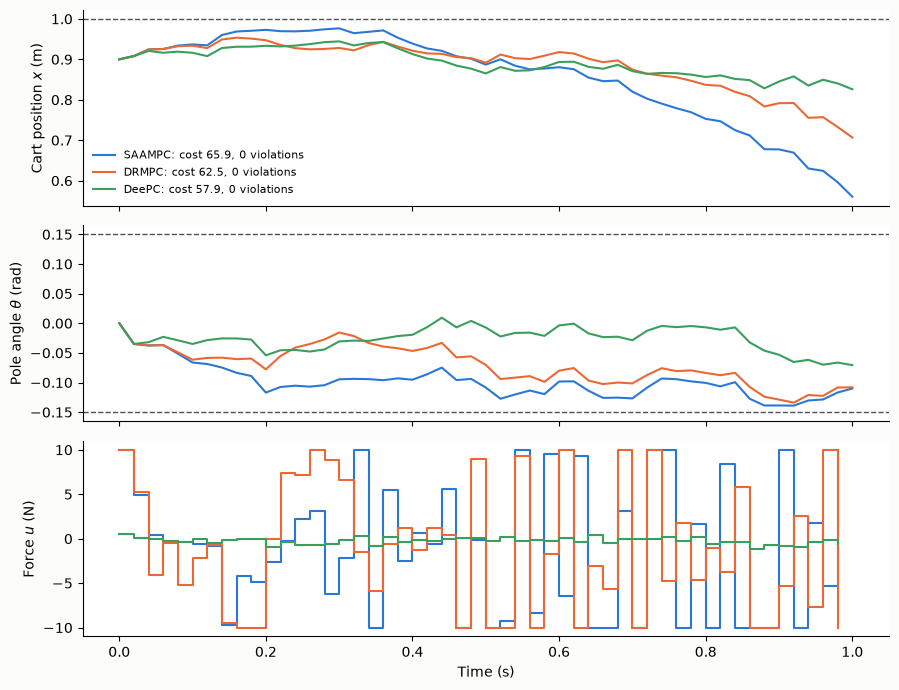

In [5]:
rng_data, rng_noise = trial_rngs(SEED, 0)
Z, Y = dataset(135, rng_data)
W = rng_noise.normal(0, NOISE, (STEPS, n))
L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
runs = {"SAAMPC": run_drmpc(L_hat, Z, Y, 0.0, 0.0, W),
        "DRMPC": run_drmpc(L_hat, Z, Y, eps1, eps2, W),
        "DeePC": run_deepc(Z, Y, LAMBDA_G[135], W)}

t = np.arange(STEPS + 1) * 0.02
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True, facecolor="#fcfcfb")
for name, result in runs.items():
    if result is None:
        print(f"{name} failed")
        continue
    X, U = result
    cost, violations = drmpc.closed_loop_metrics(X, **spec)
    axes[0].plot(t, X[:, 0], color=COLORS[name], label=f"{name}: cost {cost:.1f}, {violations} violations")
    axes[1].plot(t, X[:, 2], color=COLORS[name])
    axes[2].step(t[:-1], U[:, 0], where="post", color=COLORS[name])
axes[0].axhline(WALL, color="#52514e", linestyle="--", linewidth=1)
for bound in (-0.15, 0.15):
    axes[1].axhline(bound, color="#52514e", linestyle="--", linewidth=1)
axes[0].set_ylabel("Cart position $x$ (m)")
axes[1].set_ylabel("Pole angle $\\theta$ (rad)")
axes[2].set_ylabel("Force $u$ (N)")
axes[2].set_xlabel("Time (s)")
axes[0].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Comparison by dataset size

10 trials per N, trial k from `trial_rngs(SEED, k)`, so SAAMPC and DRMPC see exactly the runs from the DRMPC notebook's Fig. 2. DeePC uses the λ_g chosen above for that N. A run counts as failed if the solver gives up.

In [6]:
TRIALS = 10
results = {}
for N in SIZES:
    runs_n = {name: [] for name in COLORS}
    for trial in range(TRIALS):
        rng_data, rng_noise = trial_rngs(SEED, trial)
        Z, Y = dataset(N, rng_data)
        W = rng_noise.normal(0, NOISE, (STEPS, n))
        L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
        runs_n["SAAMPC"].append(metrics(run_drmpc(L_hat, Z, Y, 0.0, 0.0, W)))
        runs_n["DRMPC"].append(metrics(run_drmpc(L_hat, Z, Y, eps1, eps2, W)))
        runs_n["DeePC"].append(metrics(run_deepc(Z, Y, LAMBDA_G[N], W)))
    results[N] = {name: np.array(r) for name, r in runs_n.items()}
    for name, r in results[N].items():
        costs, violations = r.T
        print(f"N={N:<3} {name:<6}: failed {np.isnan(costs).sum()}/{TRIALS} | "
              f"cost median {np.nanmedian(costs):.1f} | violations median {np.nanmedian(violations):.0f}, "
              f"runs with any {np.sum(violations > 0)}/{TRIALS}")

/Users/awolf/Code/optimization/DRMPC-Robotics-Finance/deempc/../core/deempc.py:67: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve(solver=cp.CLARABEL)


N=35  SAAMPC: failed 0/10 | cost median 64.4 | violations median 23, runs with any 7/10
N=35  DRMPC : failed 0/10 | cost median 65.5 | violations median 28, runs with any 8/10
N=35  DeePC : failed 0/10 | cost median 75.5 | violations median 32, runs with any 9/10
N=60  SAAMPC: failed 0/10 | cost median 63.6 | violations median 6, runs with any 6/10
N=60  DRMPC : failed 0/10 | cost median 60.7 | violations median 2, runs with any 5/10
N=60  DeePC : failed 0/10 | cost median 61.1 | violations median 17, runs with any 7/10
N=100 SAAMPC: failed 0/10 | cost median 60.2 | violations median 0, runs with any 4/10
N=100 DRMPC : failed 0/10 | cost median 60.9 | violations median 0, runs with any 4/10
N=100 DeePC : failed 0/10 | cost median 59.3 | violations median 3, runs with any 6/10
N=135 SAAMPC: failed 0/10 | cost median 60.8 | violations median 0, runs with any 4/10
N=135 DRMPC : failed 0/10 | cost median 59.8 | violations median 0, runs with any 4/10
N=135 DeePC : failed 0/10 | cost median

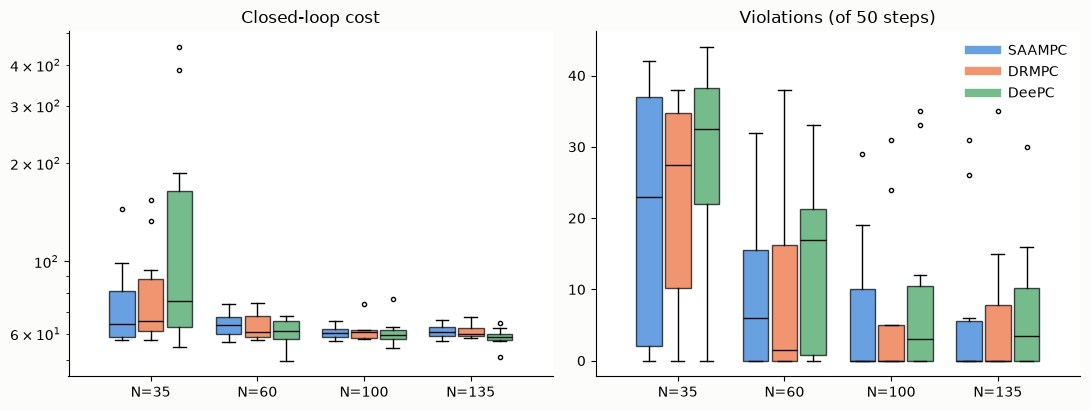

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor="#fcfcfb")
positions = np.arange(len(SIZES))
for ax, column, title in [(axes[0], 0, "Closed-loop cost"), (axes[1], 1, f"Violations (of {STEPS} steps)")]:
    for k, name in enumerate(COLORS):
        data = [results[N][name][:, column] for N in SIZES]
        data = [d[~np.isnan(d)] for d in data]
        box = ax.boxplot(data, positions=positions + (k - 1) * 0.27, widths=0.24, patch_artist=True,
                         medianprops=dict(color="#0b0b0b"), flierprops=dict(markersize=3))
        for patch in box["boxes"]:
            patch.set(facecolor=COLORS[name], alpha=0.7)
        ax.plot([], [], color=COLORS[name], linewidth=6, alpha=0.7, label=name)
    ax.set_xticks(positions, [f"N={N}" for N in SIZES])
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yscale("log")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

## Paired differences: DeePC − DRMPC per trial

Each trial gives both methods the same data and noise, so the per-trial difference cancels the luck of the draw (common random numbers). Var(A − B) = Var(A) + Var(B) − 2 Cov(A, B), and the shared noise makes Cov(A, B) large. Negative means DeePC did better.

In [8]:
for N in SIZES:
    d_cost = results[N]["DeePC"][:, 0] - results[N]["DRMPC"][:, 0]
    d_viol = results[N]["DeePC"][:, 1] - results[N]["DRMPC"][:, 1]
    print(f"N={N:<3}: cost diff median {np.nanmedian(d_cost):+6.1f}, DeePC lower in {np.sum(d_cost < 0)}/{TRIALS} | "
          f"violation diff median {np.nanmedian(d_viol):+3.0f}, DeePC fewer in {np.sum(d_viol < 0)}/{TRIALS}")

N=35 : cost diff median  +16.2, DeePC lower in 3/10 | violation diff median +10, DeePC fewer in 4/10
N=60 : cost diff median   -0.7, DeePC lower in 5/10 | violation diff median  +8, DeePC fewer in 3/10
N=100: cost diff median   +0.1, DeePC lower in 5/10 | violation diff median  +1, DeePC fewer in 3/10
N=135: cost diff median   -1.2, DeePC lower in 7/10 | violation diff median  +0, DeePC fewer in 3/10


## Conclusions

To be written after running the notebook.